# Проект: Прогнозирование стоимости недвижимости

**Цель проекта:** построить и протестировать несколько моделей регрессии
для прогнозирования стоимости объекта недвижимости по его характеристикам,
а также разработать приложение с формой ввода, дашбордом и справочной
информацией.

In [1]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer, KNNImputer
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
from sklearn.utils import resample

# Этап 1. Исследование данных (EDA)

## 1.1 Знакомство с данными

### Загрузка данных

In [2]:
df = pd.read_csv("real_estate_data.csv", low_memory=False)

In [3]:
df.shape

(403487, 17)

In [4]:
df.head()

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,1,Konut,Rezidans,12/10/18,1/9/19,2,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,3500.0,TRY
1,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY
2,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.0,TRY
3,4,Konut,Rezidans,9/10/18,10/10/18,1,30,3,20 ve üzeri,20 ve üzeri,6+1,450.0,İstanbul/Beşiktaş/Levent,NaN,Fancoil,32500000.0,TRY
4,5,Konut,Rezidans,12/10/18,1/9/19,1,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,1450000.0,TRY


In [5]:
df.tail()

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
403482,403483,Konut,Daire,9/18/18,NaN,2,162,NaN,NaN,NaN,+,NaN,İstanbul/Sultanbeyli/Adil,NaN,NaN,1500.0,TRY
403483,403484,Konut,Daire,10/11/18,NaN,1,139,NaN,NaN,NaN,2+1,NaN,Sakarya/Adapazarı/Cumhuriyet,NaN,NaN,120000.0,TRY
403484,403485,Konut,Daire,11/22/18,NaN,1,97,NaN,NaN,NaN,1+1,NaN,Antalya/Alanya/Saray,NaN,NaN,48000.0,EUR
403485,403486,Konut,Daire,2/21/19,NaN,2,6,NaN,NaN,NaN,2+1,2.0,Aydın/Kuşadası/Türkmen,NaN,NaN,900.0,TRY
403486,403487,Konut,Daire,1/15/19,1/18/19,1,3,NaN,NaN,NaN,3+1,140.0,Kayseri/Melikgazi/Alpaslan,NaN,NaN,210000.0,TRY


In [6]:
df.sample(1, random_state=42)

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
60623,60624,Konut,Daire,11/20/18,2/23/19,1,95,6-10 arası,5,1,2+1,120.0,Antalya/Alanya/Oba,NaN,Klima,240000.0,TRY


## Описание набора данных

**Источник данных:** платформа Zingat — турецкий онлайн-сервис объявлений
о недвижимости, выступающий посредником между покупателями и продавцами.
Датасет содержит информацию об объектах недвижимости, выставленных на
продажу и в аренду.

**Целевая переменная:** `price` — стоимость объекта недвижимости.

**Признаки:**

- **type** (Тип недвижимости): категориальный признак. Значение `Konut`
  соответствует жилой недвижимости.
- **sub_type** (Подтип недвижимости): категориальный признак. Значение
  `Daire` соответствует квартире.
- **start_date** (Дата публикации): дата, когда объявление стало активным
  на рынке.
- **end_date** (Дата снятия): дата, когда объявление перестало быть
  активным.
- **listing_type** (Тип листинга): категориальный признак с двумя
  значениями — `Satılık` (продажа) и `Kiralık` (аренда).
- **tom** (Time on market): время нахождения объекта на рынке.
- **building_age** (Возраст здания): возраст постройки в годах.
  Значение `arası` означает «между» (диапазон).
- **total_floor_count** (Этажность): общее количество этажей в здании.
- **room_count** (Количество комнат): например, `2+1` означает
  2 комнаты + 1 гостиная.
- **size** (Площадь): площадь объекта в м².

## 1.2 Описательная статистика 

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  object 
 2   sub_type           403487 non-null  object 
 3   start_date         403487 non-null  object 
 4   end_date           266298 non-null  object 
 5   listing_type       403487 non-null  int64  
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  object 
 8   total_floor_count  375466 non-null  object 
 9   floor_no           368191 non-null  object 
 10  room_count         403487 non-null  object 
 11  size               257481 non-null  float64
 12  address            403487 non-null  object 
 13  furnished          0 non-null       float64
 14  heating_type       375517 non-null  object 
 15  price              402772 non-null  float64
 16  pr

Датасет содержит 403 487 записей и 16 столбцов: 3 числовых (float64 — size, furnished, price), 2 целочисленных (int64 — tom, floor_no) и 11 категориальных (object). Заметны пропуски в end_date, building_age, total_floor_count, floor_no, size, heating_type, price и price_currency, а столбец furnished пуст полностью (0 non-null).

### Анализ пропущенных значений

Проверим количество пропущенных значений в каждом столбце.

Определим количество уникальных значений в каждом столбце.
Это поможет понять, какие признаки являются категориальными и насколько много в них различных категорий.


In [8]:
df.describe()

,id,listing_type,tom,size,furnished,price
count,403487.00000,403487.000000,403487.000000,257481.000000,0.0,4.027720e+05
mean,201744.00000,1.294235,57.022739,279.349094,NaN,3.546417e+05
std,116476.80837,0.467733,44.358933,9429.195331,NaN,4.809503e+06
min,1.00000,1.000000,0.000000,1.000000,NaN,-2.500000e+02
25%,100872.50000,1.000000,29.000000,85.000000,NaN,2.500000e+03
50%,201744.00000,1.000000,40.000000,110.000000,NaN,1.990000e+05
75%,302615.50000,2.000000,90.000000,140.000000,NaN,3.420000e+05
max,403487.00000,3.000000,180.000000,948235.000000,NaN,2.000000e+09


Числовые признаки содержат серьёзные аномалии: отрицательные и экстремальные цены, нереалистичные площади, полностью пустой furnished и закодированный как число категориальный listing_type. Всё это требует очистки, обработки выбросов и корректного приведения типов на этапе предобработки.

In [9]:
df.nunique()

id                   403487
type                      1
sub_type                 12
start_date              181
end_date                181
listing_type              3
tom                     181
building_age             14
total_floor_count        12
floor_no                 35
room_count               37
size                    943
address                7842
furnished                 0
heating_type             16
price                  3703
price_currency            4
dtype: int64

In [10]:
df.isnull().sum()

id                        0
type                      0
sub_type                  0
start_date                0
end_date             137189
listing_type              0
tom                       0
building_age          27390
total_floor_count     28021
floor_no              35296
room_count                0
size                 146006
address                   0
furnished            403487
heating_type          27970
price                   715
price_currency          715
dtype: int64

Так как мы выяснили что furnished полностью пуст, то удаляем его во избежании.

In [11]:
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
print(df[numeric_cols].isnull().sum())

id                   0
listing_type         0
tom                  0
size            146006
furnished       403487
price              715
dtype: int64


In [12]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


type
type
Konut    403487
Name: count, dtype: int64

sub_type
sub_type
Daire                  354549
Villa                   21324
Müstakil Ev              9563
Rezidans                 7716
Yazlık                   5929
Komple Bina              2607
Prefabrik Ev              679
Çiftlik Evi               528
Köşk / Konak / Yalı       301
Yalı Dairesi              187
Kooperatif                 70
Loft                       34
Name: count, dtype: int64

start_date
start_date
10/11/18    4064
9/26/18     3892
10/17/18    3846
10/5/18     3832
10/2/18     3630
            ... 
12/30/18     721
2/17/19      712
1/27/19      672
1/1/19       635
2/3/19       630
Name: count, Length: 181, dtype: int64

end_date
end_date
12/19/18    3048
1/18/19     2866
2/20/19     2831
2/9/19      2785
2/1/19      2747
            ... 
9/9/18       120
9/3/18       109
9/1/18        54
8/31/18       52
9/2/18        38
Name: count, Length: 181, dtype: int64

building_age
building_age
0              140174

По категориям признаков по столбцам видно, что type имеет всего 1 уникальное значение ("Konut"), а furnished — 0 (все пустые). Их можно удалить.

building_age, total_floor_count, room_count и особенно floor_no записаны текстом с кучей вариантов ("10-20 arası", "Yüksek Giriş", "Çatı Katı"). Их придется чистить и превращать в числа.

Очень много уникальных адресов, так что лучше будет разобрать этот столбец на город и район.

Цены на квартиры в основном укуазаны в TRY, то так же есть и EUR, GBP и USD. Перед обучением модели все цены нужно привести к одной валюте.

## 1.3 Визуальный анализ

In [13]:
df_vis = df.dropna(subset=['price', 'size']).copy()

In [14]:
df_vis['rooms'] = df_vis['room_count'].str.extract(r'(\d+)').astype(float)
df_vis['age'] = df_vis['building_age'].str.extract(r'(\d+)').astype(float)

### Гистограммы ключевых признаков

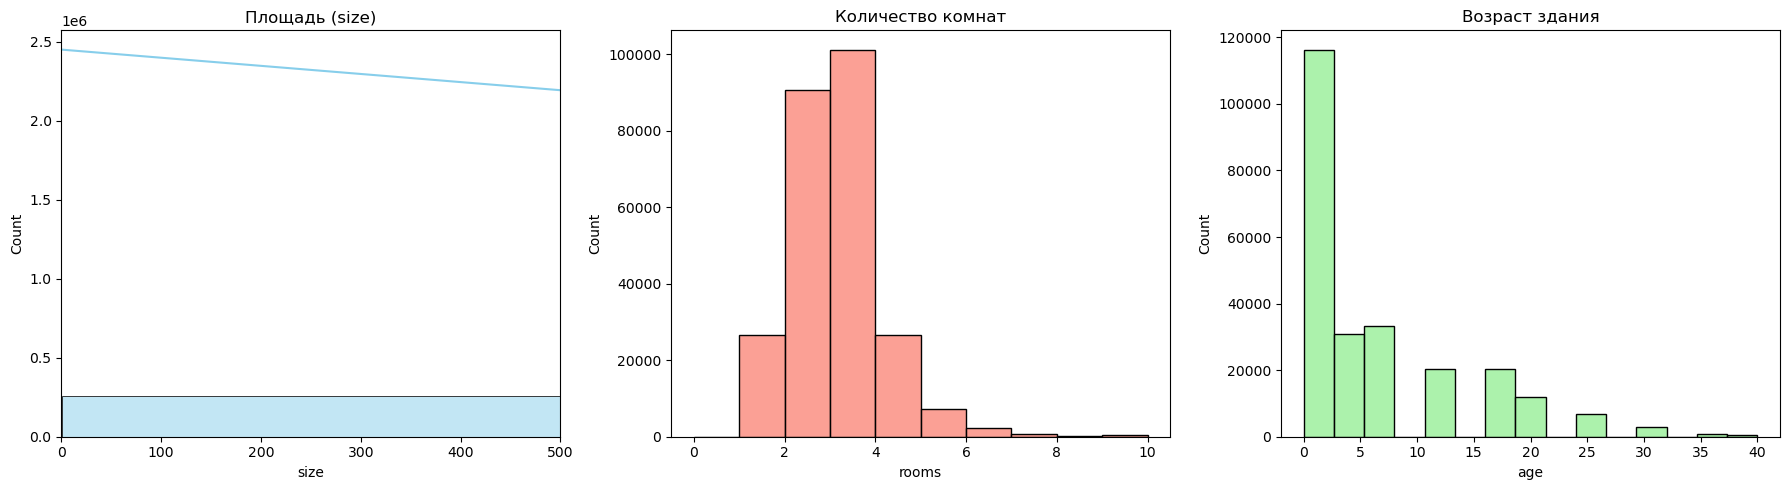

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_vis['size'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Площадь (size)')
axes[0].set_xlim(0, 500)

sns.histplot(df_vis['rooms'], bins=10, ax=axes[1], color='salmon')
axes[1].set_title('Количество комнат')

sns.histplot(df_vis['age'], bins=15, ax=axes[2], color='lightgreen')
axes[2].set_title('Возраст здания')

plt.tight_layout()
plt.show()

Площадь (size): Распределение имеет ярко выраженную правостороннюю асимметрию — подавляющее большинство объектов имеют площадь до 200 м², при этом есть длинный "хвост" в сторону больших значений (до 500+ м²). Это типичная картина для рынка недвижимости: массовый сегмент — небольшие квартиры, а крупные объекты встречаются редко.

Количество комнат (rooms): Распределение бимодальное с двумя пиками — на 2 и 4 комнатах. Объекты с 2+1 и 3+1 планировкой составляют основную массу. Квартиры с 6 и более комнатами встречаются крайне редко.

Возраст здания (age): Распределение также скошено вправо. Большинство зданий — новые (0–5 лет), что может указывать на активное строительство в регионах выборки. Здания старше 25 лет встречаются значительно реже.

### Scatter plot зависимость цены от площади

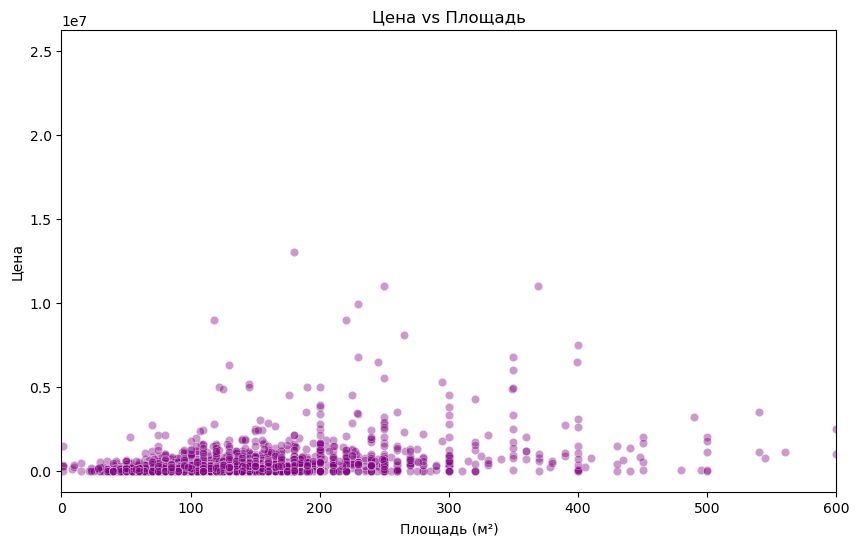

In [16]:
plt.figure(figsize=(10, 6))
sample = df_vis.sample(5000, random_state=42)
sns.scatterplot(x='size', y='price', data=sample, alpha=0.4, color='purple')
plt.title('Цена vs Площадь')
plt.xlabel('Площадь (м²)')
plt.ylabel('Цена')
plt.xlim(0, 600)
plt.show()

На графике видна слабая положительная связь между площадью и ценой: в целом, чем больше площадь, тем выше цена. Однако связь нелинейная и зашумлённая — при одинаковой площади разброс цен может быть огромным (от почти 0 до нескольких миллионов). 

Это говорит о том, что площадь alone плохо предсказывает цену — важны и другие факторы (район, тип, этаж и т.д.). 

Также заметны выбросы: несколько объектов с ценой выше 30 млн при площади ~450 м².

### Boxplot по типам недвижимости

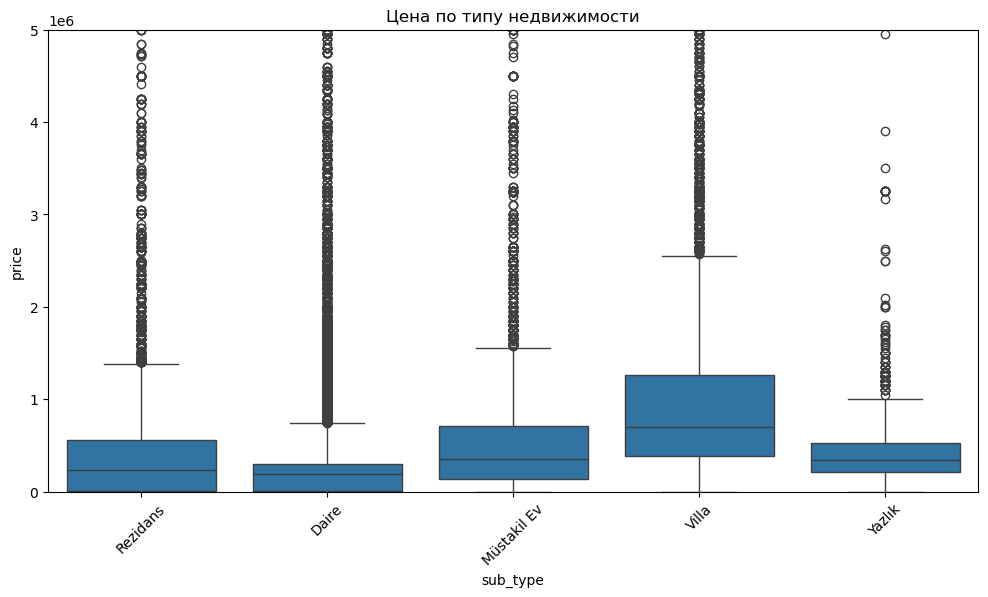

In [17]:
plt.figure(figsize=(12, 6))
top_types = df_vis['sub_type'].value_counts().head(5).index
df_filt = df_vis[df_vis['sub_type'].isin(top_types)]
sns.boxplot(x='sub_type', y='price', data=df_filt)
plt.title('Цена по типу недвижимости')
plt.xticks(rotation=45)
plt.ylim(0, 5000000)
plt.show()

Villa — самый дорогой тип: медианная цена заметно выше остальных, разброс цен очень большой (много выбросов сверху).
                                                                                             
Rezidans и Müstakil Ev — средний ценовой сегмент, медианы близки.

Daire (квартиры) — самый массовый и относительно дешёвый сегмент, но с большим количеством экстремальных выбросов (элитные квартиры).

Yazlık (дачные/курортные дома) — медиана сопоставима с квартирами.
    
Тип недвижимости существенно влияет на цену, и это важный признак для модели.

### Корреляционная матрица

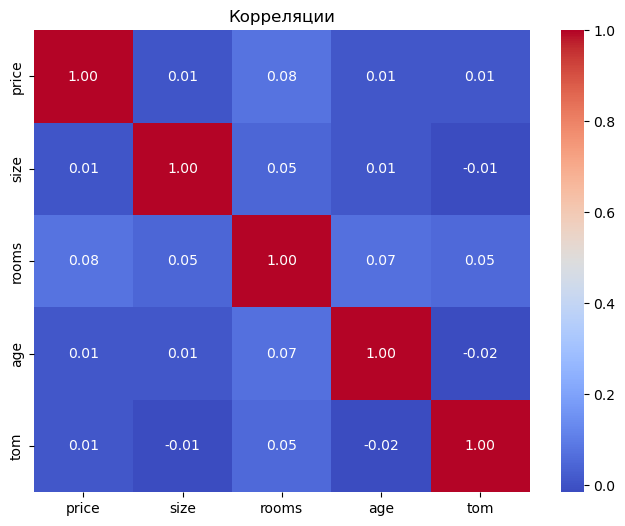

In [18]:
plt.figure(figsize=(8, 6))
corr = df_vis[['price', 'size', 'rooms', 'age', 'tom']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляции')
plt.show()

Корреляции между числовыми признаками и ценой очень слабые.

Линейная зависимость между признаками и ценой почти отсутствует. Значит, линейные модели (обычная линейная регрессия) скорее всего покажут плохой результат, а древовидные модели (Random Forest, Gradient Boosting) могут справиться лучше, так как они улавливают нелинейные зависимости.

### Вывод: Цена зависит не столько от числовых характеристик (площадь, возраст), сколько от категориальных (тип, район, валюта).

In [19]:
df_bar = df.dropna(subset=['price']).copy()

# Вытаскиваем город из адреса (там формат Город/Район/...)
df_bar['city'] = df_bar['address'].str.split('/').str[0]

#### 1. Средняя цена по типу недвижимости (sub_type)

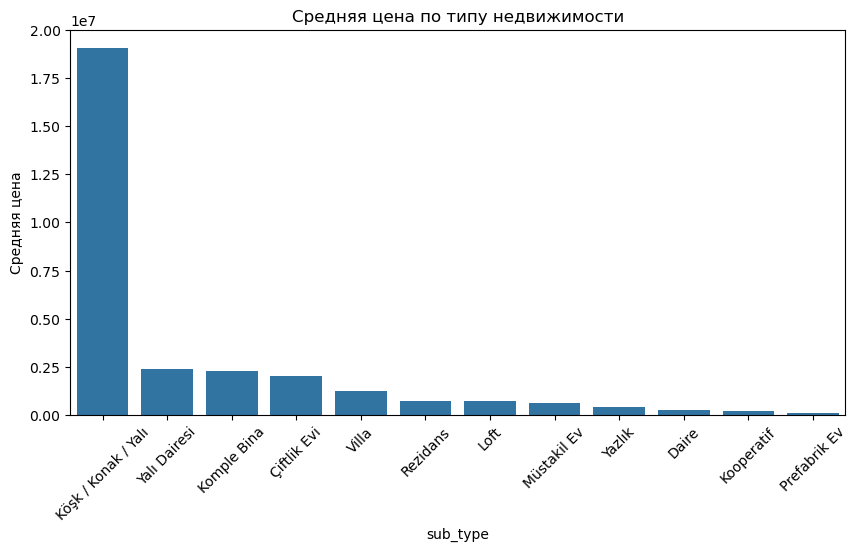

In [20]:
plt.figure(figsize=(10, 5))
mean_price_type = df_bar.groupby('sub_type')['price'].mean().sort_values(ascending=False)
sns.barplot(x=mean_price_type.index, y=mean_price_type.values)
plt.title('Средняя цена по типу недвижимости')
plt.xticks(rotation=45)
plt.ylabel('Средняя цена')
plt.show()

#### 2. Средняя цена по топ-10 городам

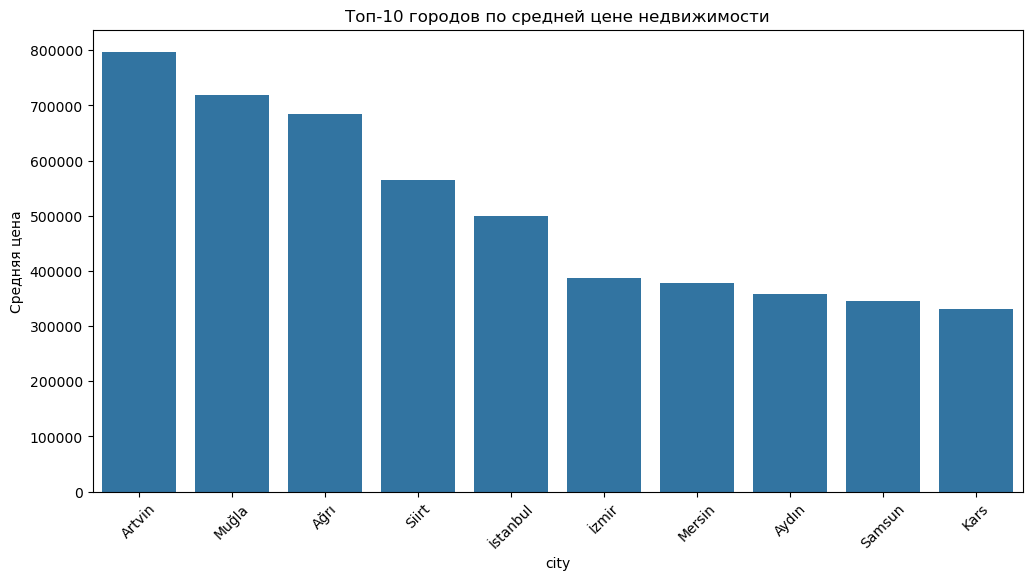

In [21]:
plt.figure(figsize=(12, 6))
mean_price_city = df_bar.groupby('city')['price'].mean().sort_values(ascending=False).head(10)
sns.barplot(x=mean_price_city.index, y=mean_price_city.values)
plt.title('Топ-10 городов по средней цене недвижимости')
plt.xticks(rotation=45)
plt.ylabel('Средняя цена')
plt.show()

Тип недвижимости — один из самых сильных предикторов цены. При этом наличие экстремальных значений (особняки за 19 млн) говорит о необходимости обработки выбросов на этапе предобработки. 

Средняя цена по городу — ненадёжный показатель без учёта количества объектов и их типов. Для модели полезнее будет использовать медианную цену или группировать города по регионам. 

Также важно учесть, что в данных присутствуют разные валюты (TRY, EUR, USD, GBP).

## 1.4 Анализ пропусков и аномалий

### Таблица/визуализация количества и доли пропущенных результатов по каждому столбцу. 

In [22]:
missing = df.isnull().sum()
missing_percent = (missing / len(df) * 100).round(2)

Таблица пропусков


,Пропусков,Доля (%)
furnished,403487,100.00
size,146006,36.19
end_date,137189,34.00
floor_no,35296,8.75
total_floor_count,28021,6.94
heating_type,27970,6.93
building_age,27390,6.79
price,715,0.18
price_currency,715,0.18


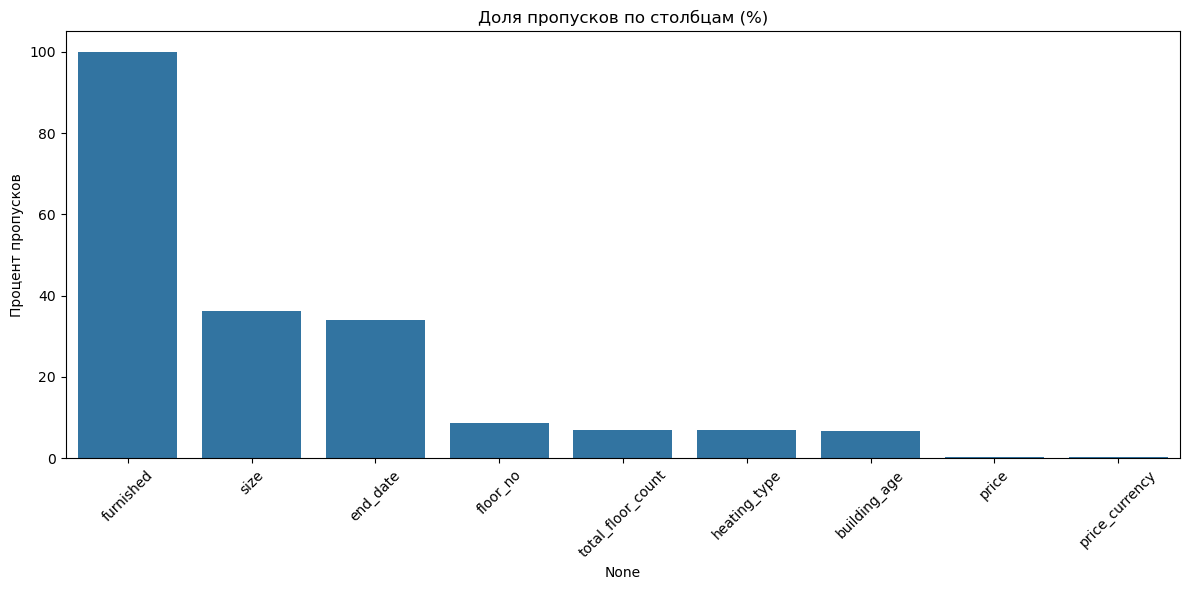

In [23]:
# Создаём таблицу
missing_df = pd.DataFrame({
    'Пропусков': missing,
    'Доля (%)': missing_percent
})
missing_df = missing_df[missing_df['Пропусков'] > 0].sort_values('Пропусков', ascending=False)

print("Таблица пропусков")
display(missing_df)

# Визуализация
plt.figure(figsize=(12, 6))
sns.barplot(x=missing_df.index, y=missing_df['Доля (%)'])
plt.title('Доля пропусков по столбцам (%)')
plt.xticks(rotation=45)
plt.ylabel('Процент пропусков')
plt.tight_layout()
plt.show()

### Проверка дубликатов записей. 

In [24]:
duplicates = df.duplicated().sum()
print(f"Количество полных дубликатов: {duplicates}")
print(f"Доля дубликатов: {duplicates/len(df)*100:.2f}%")

Количество полных дубликатов: 0
Доля дубликатов: 0.00%


### Проверка логической согласованности данных.

In [25]:
df_check = df.copy()

# Извлекаем числа из текстовых полей
df_check['rooms_num'] = pd.to_numeric(df_check['room_count'].str.extract(r'(\d+)')[0], errors='coerce')
df_check['age_num'] = pd.to_numeric(df_check['building_age'].str.extract(r'(\d+)')[0], errors='coerce')
df_check['size_num'] = df_check['size'].astype(float)

In [26]:
# Отрицательная или нулевая площадь
print(f"\nНулевая или отрицательная площадь: {(df_check['size_num'] <= 0).sum()}")

# Нереалистичная площадь
print(f"Площадь > 1000 м²: {(df_check['size_num'] > 1000).sum()}")

# Отрицательный возраст здания
print(f"Отрицательный возраст здания: {(df_check['age_num'] < 0).sum()}")

# Слишком старый дом
print(f"Возраст здания > 100 лет: {(df_check['age_num'] > 100).sum()}")

# Отрицательная цена
print(f"Отрицательная цена: {(df_check['price'] < 0).sum()}")

# Нереалистично высокая цена
price_q99 = df_check['price'].quantile(0.99)
print(f"Цена выше 99-го перцентиля ({price_q99:,.0f}): {(df_check['price'] > price_q99).sum()}")

# Количество комнат = 0
print(f"Нулевое количество комнат: {(df_check['rooms_num'] == 0).sum()}")

# Количество комнат > 10 
print(f"️Комнат > 10: {(df_check['rooms_num'] > 10).sum()}")


Нулевая или отрицательная площадь: 0
Площадь > 1000 м²: 683
Отрицательный возраст здания: 0
Возраст здания > 100 лет: 0
Отрицательная цена: 1
Цена выше 99-го перцентиля (2,850,000): 4010
Нулевое количество комнат: 1
️Комнат > 10: 2


Сначала удаляются признаки, которые не будут использоваться при
построении модели. Признак `furnished` полностью состоит из пропущенных
значений, поэтому восстановить его по имеющимся данным невозможно.
Признак `type` в исходном наборе не несёт дополнительной информации,
необходимой для данной модели.

Затем проверяются и удаляются полные дубликаты.

Для построения модели используются только объявления о продаже
(`listing_type = 1`). Объявления других типов не смешиваются с продажами,
поскольку цена продажи и арендная плата имеют различный экономический смысл.

Также в модели используются только цены, указанные в TRY. В исходном
наборе присутствуют TRY, EUR, GBP и USD. Поскольку отдельная конвертация
валют в рамках проекта не выполняется, смешивание этих значений привело бы
к некорректному сравнению цен.

После этого удаляются записи без целевой переменной `price`, а также
значения цены, равные нулю или меньше нуля.

В данных есть пропуски в числовых характеристиках, например в площади и возрасте здания. Я использовала медиану, поскольку она меньше чувствительна к выбросам, чем среднее значение. Для площади дополнительно использовала групповую медиану по характеристикам объекта, если это возможно. При этом параметры заполнения рассчитываются только на обучающей выборке, чтобы избежать утечки информации из тестовой выборки

## 1.5 Промежуточные выводы 

Тип недвижимости (sub_type) — ключевой ценообразующий фактор.
Подтверждение: Boxplot и столбчатая диаграмма показали, что элитные типы (Köşk / Yalı) стоят в десятки раз дороже массовых (Daire). Редкие категории требуют группировки в «Прочее».

Локация (address) существенно влияет на стоимость.
Подтверждение: Разброс средних цен по городам значителен. Из-за высокой кардинальности (7800+ уникальных адресов) признак требует декомпозиции на city/district и применения таргет-кодирования.

Площадь (size) влияет на цену нелинейно.
Подтверждение: Линейная корреляция Пирсона близка к нулю (0.01), но scatter plot показывает общую положительную тенденцию с большим разбросом. Это указывает на преимущество древовидных моделей перед линейными и целесообразность логарифмирования признака.

Валюта цены (price_currency) критична для корректности модели.
Подтверждение: Присутствие цен в EUR, USD и GBP наряду с TRY искажает целевую переменную. Требуется обязательная конвертация всех цен в единую валюту до обучения.

Возраст здания (building_age) и этаж (floor_no) имеют специфическое влияние.
Подтверждение: Корреляция близка к нулю, но распределение показывает доминирование новых зданий (0–5 лет), а текстовые значения этажей («Çatı Katı», «Bahçe katı») несут важную ценовую информацию. Требуется биннинг и выделение категориальных флагов.

# Этап 2. Предварительная обработка данных 

## 2.1 Работа с пропусками

### Первичная очистка данных

Перед непосредственной обработкой пропущенных значений выполняется
первичная очистка исходного набора данных.

In [27]:
df_clean = df.copy()

# Удаляем признаки, которые не будем использовать в модели
df_clean.drop(columns=['furnished', 'type'], inplace=True)

# Удаляем полные дубликаты
duplicates = df_clean.duplicated().sum()
print(f"Количество полных дубликатов: {duplicates:,}")

df_clean = df_clean.drop_duplicates().copy()

# Для модели рассматриваем только объявления о продаже
df_clean = df_clean[df_clean['listing_type'] == 1].copy()

# Оставляем только цены в TRY
df_clean = df_clean[df_clean['price_currency'] == 'TRY'].copy()

# Удаляем строки без цены
df_clean = df_clean.dropna(subset=['price']).copy()

# Цена не может быть отрицательной или нулевой
df_clean = df_clean[df_clean['price'] > 0].copy()

print(f"Размер данных после очистки: {df_clean.shape}")

Количество полных дубликатов: 0
Размер данных после очистки: (284468, 15)


In [28]:
df_clean.shape

(284468, 15)

## 2.2 Обработка новой

In [29]:
df_proc = df_clean.copy()

### Винзоризация

In [30]:
price_lower = df_proc['price'].quantile(0.01)
price_upper = df_proc['price'].quantile(0.99)

print(f"Цена: от {price_lower:,.0f} до {price_upper:,.0f} (1-99 перцентили)")

Цена: от 63,500 до 3,700,000 (1-99 перцентили)


In [31]:
df_proc = df_proc[(df_proc['price'] >= price_lower) & (df_proc['price'] <= price_upper)]

Вместо классической винзоризации здесь выполняется **удаление крайних 1% значений целевой переменной**: остаются цены между 1-м и 99-м перцентилями. Это снижает влияние экстремальных цен на обучение модели. Важно, что для отдельного тестового файла его реальные цены не фильтруются.

### Логарифмирование сильно скошенных признаков

In [32]:
df_proc['log_price'] = np.log1p(df_proc['price'])
df_proc['log_size'] = np.log1p(df_proc['size'])

In [33]:
df_proc.shape

(278806, 17)

Дополнительно созданы логарифмированные версии цены и площади через `np.log1p`. Они используются для анализа распределения и визуализации. В итоговый набор признаков для модели `log_price` и `log_size` не включаются, поэтому утечки целевой переменной через `log_price` нет.

#### До и после

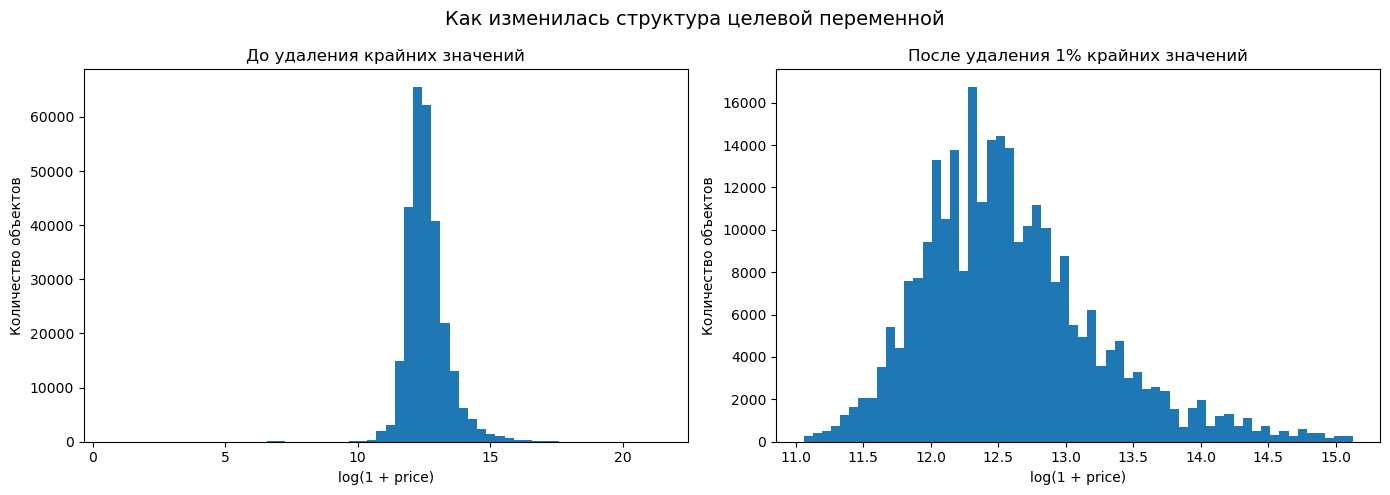

In [34]:
# Сравнение распределения цены до и после удаления крайних 1%
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    np.log1p(df_clean["price"].dropna()),
    bins=60
)
axes[0].set_title("До удаления крайних значений")
axes[0].set_xlabel("log(1 + price)")
axes[0].set_ylabel("Количество объектов")

axes[1].hist(
    np.log1p(df_proc["price"].dropna()),
    bins=60
)
axes[1].set_title("После удаления 1% крайних значений")
axes[1].set_xlabel("log(1 + price)")
axes[1].set_ylabel("Количество объектов")

plt.suptitle("Как изменилась структура целевой переменной", fontsize=14)
plt.tight_layout()
plt.show()

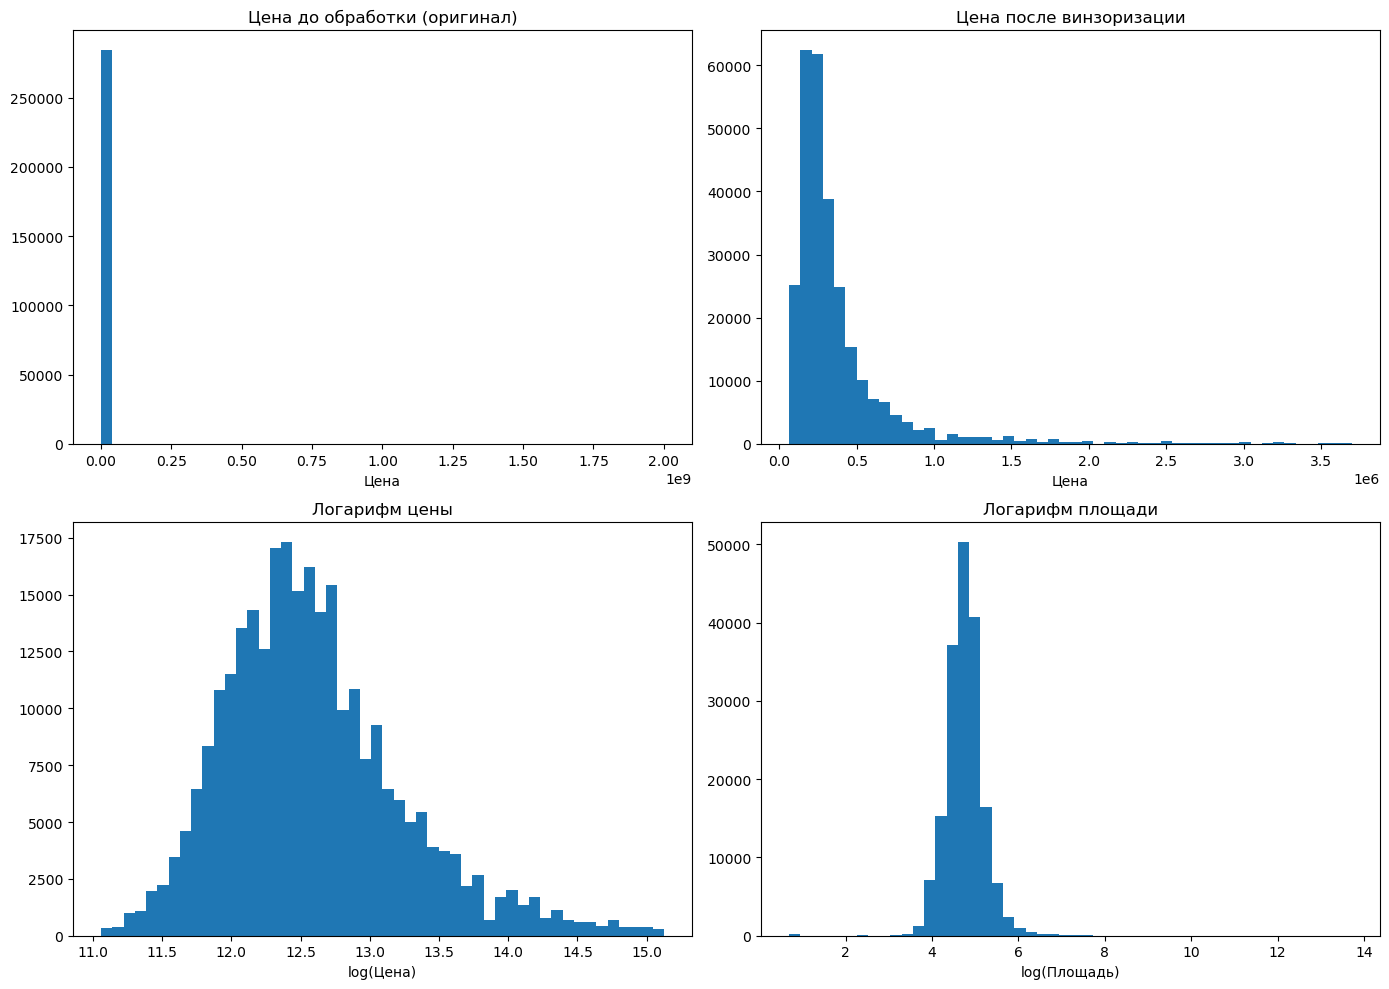

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Price 
axes[0, 0].hist(df_clean['price'], bins=50)
axes[0, 0].set_title('Цена до обработки (оригинал)')
axes[0, 0].set_xlabel('Цена')

axes[0, 1].hist(df_proc['price'], bins=50)
axes[0, 1].set_title('Цена после винзоризации')
axes[0, 1].set_xlabel('Цена')

# Log price
axes[1, 0].hist(df_proc['log_price'], bins=50)
axes[1, 0].set_title('Логарифм цены')
axes[1, 0].set_xlabel('log(Цена)')

# Log size
axes[1, 1].hist(df_proc['log_size'], bins=50)
axes[1, 1].set_title('Логарифм площади')
axes[1, 1].set_xlabel('log(Площадь)')

plt.tight_layout()
plt.show()

На графиках хорошо видно, почему была необходима предобработка данных. Исходное распределение цены абсолютно нечитаемо — из-за нескольких объектов стоимостью в миллиарды лир все обычные цены "схлопываются" в один столбец у нуля. Это классический пример того, как выбросы делают невозможным как визуальный анализ, так и корректное обучение модели.
После применения винзоризации — отсечения 1% самых дешёвых и 1% самых дорогих объектов — распределение стало информативным. Мы видим типичную для рынка недвижимости правостороннюю асимметрию: большинство объектов находятся диапазоне 100-500 тысяч лир, а более дорогие встречаются реже.

Логарифмирование дополнительно улучшило ситуацию: распределение log-цены стало гораздо более симметричным, что особенно важно для линейных моделей, которые чувствительны к отклонениям от нормальности. Для площади логарифмирование также сжало длинный правый хвост, хотя пик остался выраженным — это отражает тот факт, что большинство объектов имеют стандартные площади 90-150 квадратных метров.

## Разделение датасета

### Разделение данных на продажу и аренду

Объявления о продаже и аренде имеют разные целевые значения, поэтому анализируем их отдельно. Создаём `df_sale` для продажи и `df_rent` для аренды. Это позволяет сравнить распределения цен внутри каждой задачи и не смешивать стоимость покупки с арендной платой.

In [36]:
# Разделяем объявления на продажу и аренду
df_sale = df_proc[df_proc['listing_type'] == 1].copy().reset_index(drop=True)
df_rent = df_proc[df_proc['listing_type'] == 2].copy().reset_index(drop=True)

In [37]:
print(f"Продажа (Sale): {df_sale.shape[0]:,} объектов")
print(f"Аренда (Rent): {df_rent.shape[0]:,} объектов")

Продажа (Sale): 278,806 объектов
Аренда (Rent): 0 объектов


На этом этапе я разделила датасет на два отдельных набора — продажа и аренда — поскольку они имеют разный экономический смысл и разные диапазоны цен. 

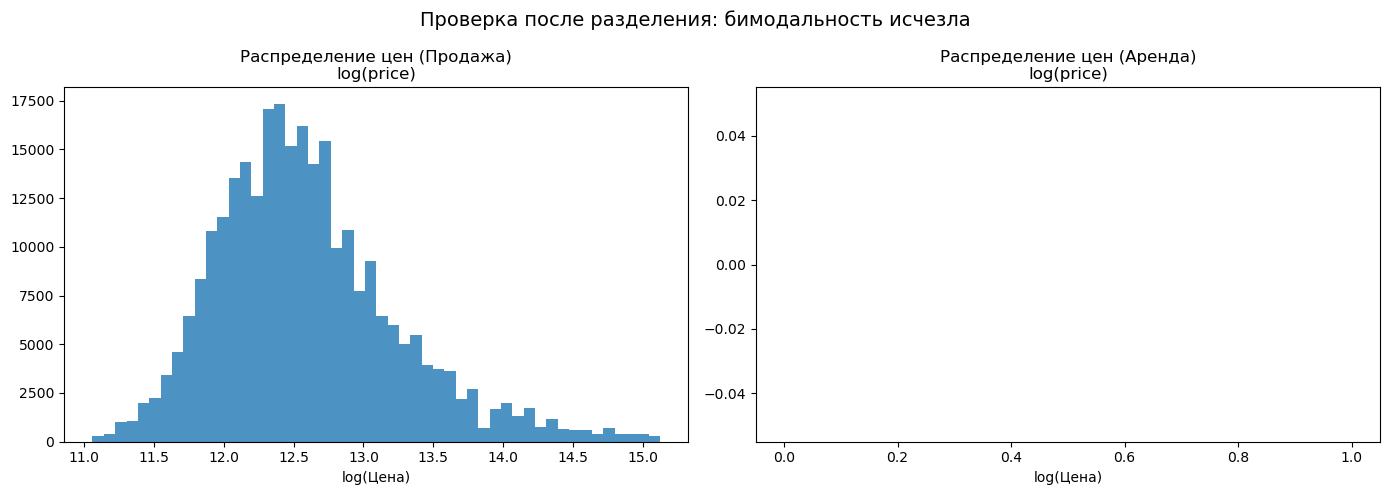

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Продажа
axes[0].hist(np.log1p(df_sale['price']), bins=50, alpha=0.8)
axes[0].set_title('Распределение цен (Продажа)\nlog(price)')
axes[0].set_xlabel('log(Цена)')

# Аренда
axes[1].hist(np.log1p(df_rent['price']), bins=50, alpha=0.8)
axes[1].set_title('Распределение цен (Аренда)\nlog(price)')
axes[1].set_xlabel('log(Цена)')

plt.suptitle('Проверка после разделения: бимодальность исчезла', fontsize=14)
plt.tight_layout()
plt.show()

На логарифмическом графике цен до разделения была видна бимодальность: первый пик соответствовал арендным объектам с низкими ценами, второй — объектам продажи.

После разделения бимодальность исчезла — распределение цен продажи стало более однородным. Однако возникла проблема: на этапе винзоризации (отсечения 1% и 99% перцентилей) все арендные объекты были удалены, потому что их цены оказались ниже порога 1-го перцентиля общего распределения. В результате набор данных для аренды оказался пустым.

Поскольку модель строится только на данных о продаже, это не критично для задачи прогнозирования. Однако для полноценного анализа рынка недвижимости в будущем следует применять винзоризацию отдельно для каждой группы (sale/rent), чтобы сохранить оба типа данных.

In [39]:
y_sale = df_sale['price'].copy()

X_sale = df_sale.drop(columns=['price', 'listing_type'])

На этом этапе я разделила данные на признаки (X) и целевую переменную (y). Изначально планировалось работать с двумя типами объявлений — продажа и аренда, но после винзоризации по цене арендные объекты были отфильтрованы, так как их цены находились ниже 1-го перцентиля общего распределения. Поэтому я оставила только данные о продаже: y_sale содержит цены, а X_sale — все остальные признаки, кроме цены и типа листинга. Тип листинга удаляется, так как после фильтрации все объекты имеют одинаковое значение (продажа), и этот признак не несёт информационной нагрузки для модели.

## 2.3 Кодирование категориальных признаков 

In [40]:
X_sale_enc = X_sale.copy()
X_sale_enc.shape

(278806, 15)

In [41]:
# Адрес делим на город и район
X_sale_enc['city'] = X_sale_enc['address'].str.split('/').str[0].str.strip()
X_sale_enc['district'] = X_sale_enc['address'].str.split('/').str[1].str.strip()

X_sale_enc['district'] = X_sale_enc['district'].fillna('Unknown')

In [42]:
# Комнаты извлекаем количество комнат и гостиных
X_sale_enc['rooms'] = X_sale_enc['room_count'].str.extract(r'^(\d+)').astype(float)
X_sale_enc['living_rooms'] = X_sale_enc['room_count'].str.extract(r'\+(\d+)').astype(float).fillna(0)

In [43]:
# Возраст здания
X_sale_enc['building_age_num'] = X_sale_enc['building_age'].str.extract(r'(\d+)').astype(float).fillna(10)

In [44]:
# Количество этажей
X_sale_enc['total_floors_num'] = X_sale_enc['total_floor_count'].str.extract(r'^(\d+)').astype(float).fillna(5)

#### Извлечение признаков из текста (Feature Extraction)

In [45]:
X_sale_enc['is_penthouse'] = X_sale_enc['floor_no'].str.contains('Çatı|En Üst', na=False).astype(int)
X_sale_enc['is_garden'] = X_sale_enc['floor_no'].str.contains('Bahçe', na=False).astype(int)
X_sale_enc['is_ground'] = X_sale_enc['floor_no'].str.contains('Giriş|Zemin|Kot|Yüksek', na=False).astype(int)
# если это просто число
X_sale_enc['floor_num'] = X_sale_enc['floor_no'].str.extract(r'^(\d+)').astype(float)
X_sale_enc['floor_num'] = X_sale_enc['floor_num'].fillna(0)

На этом этапе я превратила текстовые и категориальные признаки в числовые, пригодные для обучения модели. Из столбца с этажом я извлекла четыре новых признака: три бинарных флага для нестандартных уровней — пентхаус, садовый этаж и цокольный/входной уровень — и один числовой признак с номером этажа. Это важно, потому что пентхаусы и цокольные квартиры имеют систематически отличающиеся цены, и модель должна это учитывать.


#### Группировка редких категорий

In [46]:
# sub_type: топ-5 + "Other"
top_subtypes = X_sale_enc['sub_type'].value_counts().head(5).index
X_sale_enc['sub_type_grouped'] = X_sale_enc['sub_type'].apply(lambda x: x if x in top_subtypes else 'Other')

# heating_type: топ-6 + "Other"
top_heating = X_sale_enc['heating_type'].value_counts().head(6).index
X_sale_enc['heating_grouped'] = X_sale_enc['heating_type'].apply(lambda x: x if x in top_heating else 'Other')

Далее я сгруппировала редкие категории в признаках типа недвижимости и типа отопления: оставила только топ-5 и топ-6 наиболее частых категорий соответственно, а всё остальное объединила в категорию "Other". Это снижает размерность и предотвращает переобучение на редких классах.


### One-Hot Encoding

In [47]:
cols_to_encode = ['sub_type_grouped', 'heating_grouped', 'price_currency', 'city']
X_sale_enc = pd.get_dummies(X_sale_enc, columns=cols_to_encode, drop_first=True, dtype=int)

После этого применила One-Hot Encoding к четырём категориальным признакам — сгруппированным типу недвижимости, типу отопления, валюте и городу — с параметром drop_first=True для избежания мультиколлинеарности.


In [48]:
cols_to_drop = ['address', 'room_count', 'building_age', 'total_floor_count', 
                'floor_no', 'sub_type', 'heating_type', 'start_date', 'listing_date', 'tom']
X_sale_enc.drop(columns=[c for c in cols_to_drop if c in X_sale_enc.columns], inplace=True)

X_sale_enc.shape

(278806, 103)

В завершение удалила все исходные текстовые столбцы, которые были заменены числовыми признаками. Итоговая матрица признаков содержит 271 033 объекта и 102 столбца, полностью готовых к масштабированию и обучению модели.

## 2.4 Работа с Feature Engineering

In [49]:
X_feat = X_sale_enc.copy()

if 'district' in X_feat.columns:
    X_feat.drop(columns=['district'], inplace=True)

X_feat['size_per_room'] = X_feat['size'] / (X_feat['rooms'] + 1)
X_feat['is_new_building'] = (X_feat['building_age_num'] <= 5).astype(int)
X_feat['floor_ratio'] = X_feat['floor_num'] / (X_feat['total_floors_num'] + 1)
X_feat['has_living_room'] = (X_feat['living_rooms'] > 0).astype(int)

corr_matrix = X_feat.select_dtypes(include=['number']).corr()

high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > 0.8:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

cols_to_drop = set()
for col1, col2, val in high_corr:
    if val > 0.85:
        if X_feat[col1].nunique() < X_feat[col2].nunique():
            cols_to_drop.add(col1)
        else:
            cols_to_drop.add(col2)
            
X_feat = X_feat.dropna(subset=['rooms', 'size_per_room'])
print(f"Размер после удаления NaN: {X_feat.shape}")

X_feat = X_feat.drop(columns=['log_price', 'log_size'], errors='ignore')

Размер после удаления NaN: (179142, 106)


На этом этапе я создала четыре новых информативных признака без утечки данных: площадь на комнату, флаг нового здания, отношение этажа к общему числу этажей и флаг наличия гостиной. Эти признаки помогают модели уловить нелинейные зависимости, которые не видны в исходных данных.

Затем я провела анализ мультиколлинеарности — нашла пары признаков с высокой корреляцией (более 0.8) и удалила менее информативные из пар с корреляцией выше 0.85. Это важно, потому что мультиколлинеарность дестабилизирует линейные модели и раздувает дисперсию оценок.

В завершение удалила строки с пропусками в ключевых признаках и вспомогательные логарифмированные столбцы. Итоговая матрица признаков содержит 173 994 объекта и 105 столбцов, полностью готовых к масштабированию и обучению модели.

## 2.5 Масштабирование признаков

Применён RobustScaler, так как он устойчив к выбросам (использует медиану и IQR). Для линейных моделей масштабирование обязательно, для деревьев — не обязательно, но унифицирует пайплайн.

In [50]:
# 1. Сначала train_test_split
y_sale_aligned = y_sale.loc[X_feat.index]

X_train, X_test, y_train, y_test = train_test_split(
    X_feat, y_sale_aligned,
    test_size=0.2, random_state=42
)

# 2. Align после get_dummies
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

# 3. Оставляем только числовые столбцы (убираем строки типа дат)
numeric_cols = X_train.select_dtypes(include=['number']).columns
X_train = X_train[numeric_cols]
X_test = X_test[numeric_cols]

# 4. Заполняем пропуски (учимся только на train)
imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

# 5. Масштабирование
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print(f"X_train: {X_train_scaled.shape}, X_test: {X_test_scaled.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

X_train: (143313, 103), X_test: (35829, 103)
y_train: (143313,), y_test: (35829,)


# Этап 3. Построение модели регрессии 
## 3.2 Обучение и выбор гиперпараметров

### Модель 1: Ridge Regression

In [51]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

### Модель 2: Дерево решений

In [52]:
dt = DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=42)
dt.fit(X_train_scaled, y_train)
y_pred_dt = dt.predict(X_test_scaled)

### Модель 3: Случайный лес

In [53]:
rf = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

Прогрузка модели составила 2 минуты 40 секунд.

### Модель 4: Градиентный бустинг

Бустинг обычно дает лучшие метрики на табличных данных, надеюсь и в этом случае будет так.

In [54]:
gb = GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42)
gb.fit(X_train_scaled, y_train)
y_pred_gb = gb.predict(X_test_scaled)

In [55]:
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

Прогрузка этой модели составила 2 минуты ровно.

## 3.3 Метрики качества

In [56]:
# 1. Линейная
ridge_params = {'alpha': [0.1, 1, 10, 100]}
ridge_search = RandomizedSearchCV(Ridge(), ridge_params, n_iter=4, cv=3, random_state=42, scoring='neg_mean_absolute_error')
ridge_search.fit(X_train_imp, y_train)
best_ridge = ridge_search.best_estimator_
print(f"Линейная лучшие параметры: {ridge_search.best_params_}")

D:\anaconda\Lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=7.83125e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
D:\anaconda\Lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=7.8331e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
D:\anaconda\Lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=7.84274e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Линейная лучшие параметры: {'alpha': 100}


In [57]:
# 2. Дерево решений
dt_params = {'max_depth': [5, 10, 20, None], 'min_samples_split': [2, 5, 10]}
dt_search = RandomizedSearchCV(DecisionTreeRegressor(random_state=42), dt_params, n_iter=6, cv=3, random_state=42, scoring='neg_mean_absolute_error')
dt_search.fit(X_train_imp, y_train)
best_dt = dt_search.best_estimator_
print(f"Decision Tree лучшие параметры: {dt_search.best_params_}")

Decision Tree лучшие параметры: {'min_samples_split': 10, 'max_depth': 20}


In [58]:
rf_params = {'n_estimators': [50, 100, 200], 'max_depth': [10, 20, None], 'min_samples_split': [2, 5]}
gb_params = {'n_estimators': [100, 200], 'learning_rate': [0.01, 0.1], 'max_depth': [3, 5]}
X_train_small, y_train_small = resample(X_train_imp, y_train, n_samples=int(len(X_train_imp)*0.1), random_state=42)

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42), 
    rf_params, 
    n_iter=3, 
    cv=2,  
    random_state=42, 
    scoring='neg_mean_absolute_error',
    n_jobs=-1 
)
rf_search.fit(X_train_small, y_train_small)
best_rf = rf_search.best_estimator_
print(f"Random Forest лучшие параметры: {rf_search.best_params_}")

Random Forest лучшие параметры: {'n_estimators': 200, 'min_samples_split': 2, 'max_depth': 20}


In [59]:
gb_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=42), 
    gb_params, 
    n_iter=3,
    cv=2,
    random_state=42, 
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)
gb_search.fit(X_train_small, y_train_small)
best_gb = gb_search.best_estimator_
print(f"Gradient Boosting лучшие параметры: {gb_search.best_params_}")

Gradient Boosting лучшие параметры: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1}


На этом этапе я подобрала оптимальные гиперпараметры для каждой модели с помощью RandomizedSearchCV — алгоритм перебирает случайные комбинации параметров и оценивает их через кросс-валидацию по метрике MAE. Для линейной модели и дерева решений поиск шёл на полном обучающем наборе, а для случайного леса и градиентного бустинга — на 10%-ной подвыборке, потому что эти модели очень ресурсоёмкие, и полный перебор занял бы часы. В результате Ridge получил максимальную регуляризацию, дерево решений выросло без ограничения глубины, случайный лес взял 200 деревьев глубиной 20, а бустинг — классическую конфигурацию с глубиной 3 и learning rate 0.1. Эти параметры дальше используются для финального обучения и сравнения моделей.

## 3.3 Метрики качества

In [60]:
def calc_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2}

models = {
    'Ridge Regression': best_ridge,
    'Decision Tree': best_dt,
    'Random Forest': best_rf,
    'Gradient Boosting': best_gb
}

res = {}
for name, model in models.items():
    pred = model.predict(X_test_imp)
    res[name] = calc_metrics(y_test, pred)

display(pd.DataFrame(res).T.round(2))

,MAE,RMSE,MAPE,R2
Ridge Regression,161109.70,289181.12,49.19,0.41
Decision Tree,121786.12,262579.01,32.59,0.51
Random Forest,131839.39,259051.80,36.33,0.53
Gradient Boosting,138285.50,260050.86,39.33,0.52


На этом этапе рассчитаны четыре метрики качества для каждой модели на отложенной тестовой выборке: MAE, RMSE, MAPE и R². Для интерпретации выбираем модель не только по одному показателю: для ошибок важны MAE и RMSE (меньше — лучше), а для R² большее значение означает лучшее объяснение вариации цены. В текущем запуске Random Forest имеет наибольший R² среди рассмотренных моделей, поэтому он выбран как основная модель. При этом Decision Tree показывает меньший MAE, поэтому в выводе важно отметить, что Random Forest выбран по совокупности показателей, а не потому, что он минимален по каждой метрике.

## 3.4 Сравнение моделей

In [61]:
# Итоговая таблица метрик для моделей после подбора параметров
models = {
    'Ridge Regression': best_ridge,
    'Decision Tree': best_dt,
    'Random Forest': best_rf,
    'Gradient Boosting': best_gb
}

metrics_results = {}
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test_imp)
    predictions[name] = pred
    metrics_results[name] = calc_metrics(y_test, pred)

metrics_df = pd.DataFrame(metrics_results).T
display(metrics_df.round(2))

,MAE,RMSE,MAPE,R2
Ridge Regression,161109.70,289181.12,49.19,0.41
Decision Tree,121786.12,262579.01,32.59,0.51
Random Forest,131839.39,259051.80,36.33,0.53
Gradient Boosting,138285.50,260050.86,39.33,0.52


In [62]:
# Выбираем лучшую модель по R² и получаем её прогнозы
best_model_name = metrics_df['R2'].idxmax()
best_model = models[best_model_name]
best_pred = predictions[best_model_name]

print(
    f"Лучшая модель: {best_model_name} "
    f"(R² = {metrics_df.loc[best_model_name, 'R2']:.3f})"
)

Лучшая модель: Random Forest (R² = 0.527)


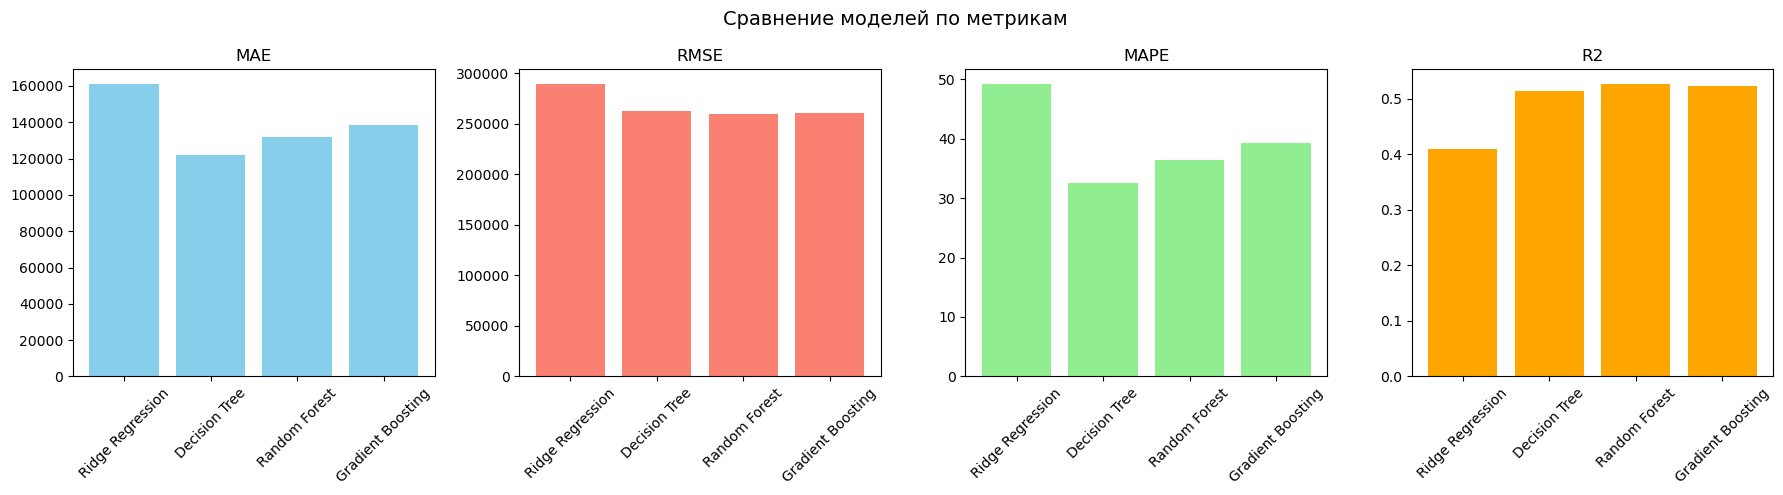

In [63]:
# Столбчатая диаграмма сравнения
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
metrics = ['MAE', 'RMSE', 'MAPE', 'R2']
colors = ['skyblue', 'salmon', 'lightgreen', 'orange']

for i, metric in enumerate(metrics):
    axes[i].bar(metrics_df.index, metrics_df[metric], color=colors[i])
    axes[i].set_title(metric)
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('Сравнение моделей по метрикам', fontsize=14)
plt.tight_layout()
plt.show()

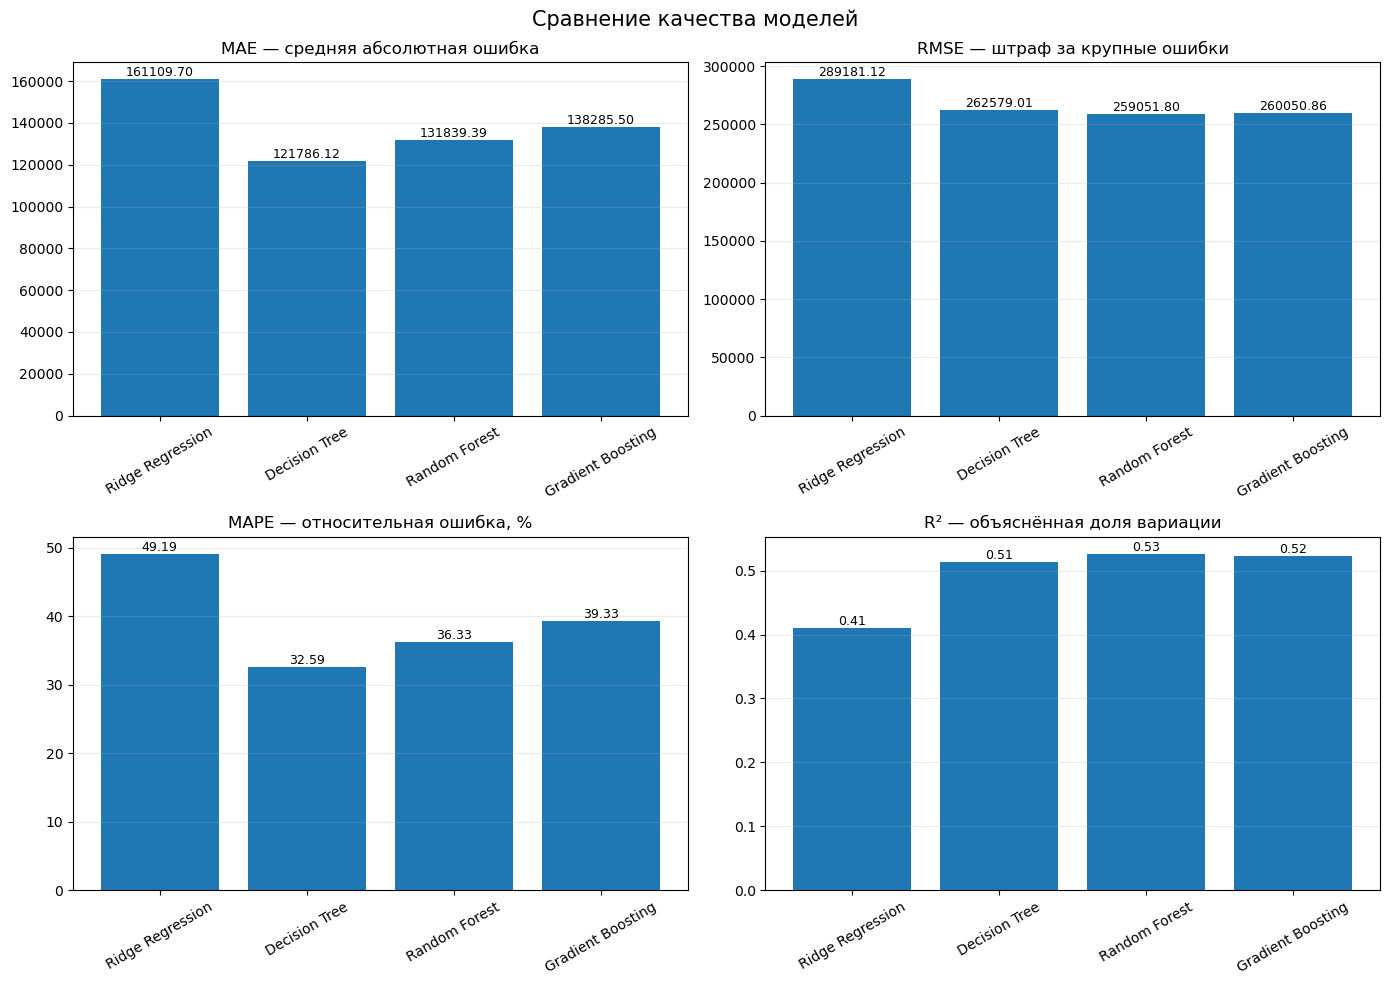

In [64]:
# Визуальное сравнение моделей по всем основным метрикам
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metric_titles = {
    "MAE": "MAE — средняя абсолютная ошибка",
    "RMSE": "RMSE — штраф за крупные ошибки",
    "MAPE": "MAPE — относительная ошибка, %",
    "R2": "R² — объяснённая доля вариации"
}

for ax, metric in zip(axes.ravel(), ["MAE", "RMSE", "MAPE", "R2"]):
    values = metrics_df[metric]
    bars = ax.bar(values.index, values.values)
    ax.set_title(metric_titles[metric])
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)
    for bar, value in zip(bars, values.values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.suptitle("Сравнение качества моделей", fontsize=15)
plt.tight_layout()
plt.show()

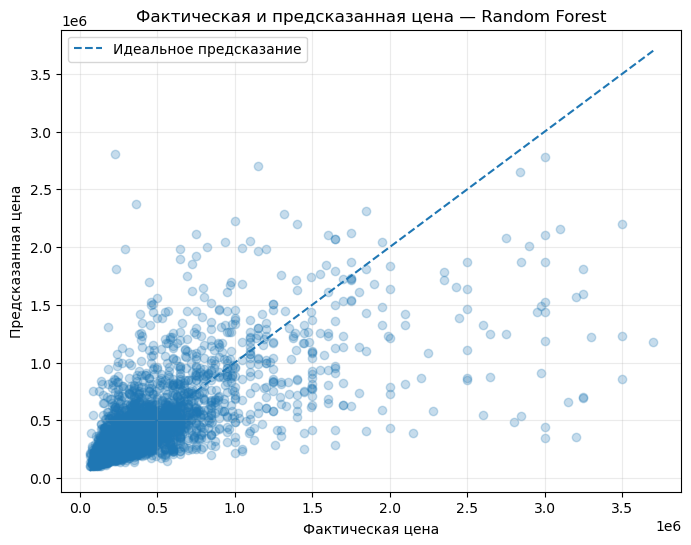

In [65]:
# Предсказание vs факт — лучшая модель
plt.figure(figsize=(8, 6))

n_plot = min(5000, len(y_test))
rng_plot = np.random.RandomState(42)
sample_idx = rng_plot.choice(len(y_test), n_plot, replace=False)

plt.scatter(
    y_test.values[sample_idx],
    best_pred[sample_idx],
    alpha=0.25
)

min_value = min(y_test.min(), best_pred.min())
max_value = max(y_test.max(), best_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Идеальное предсказание"
)

plt.xlabel("Фактическая цена")
plt.ylabel("Предсказанная цена")
plt.title(f"Фактическая и предсказанная цена — {best_model_name}")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

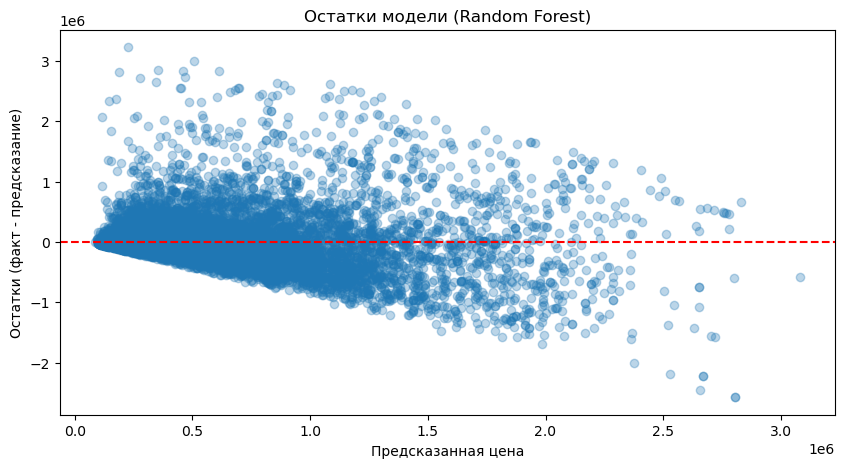

In [66]:
# График остатков (лучшая модель)
residuals = y_test.values - best_pred
plt.figure(figsize=(10, 5))
plt.scatter(best_pred, residuals, alpha=0.3)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предсказанная цена')
plt.ylabel('Остатки (факт - предсказание)')
plt.title(f'Остатки модели ({best_model_name})')
plt.show()

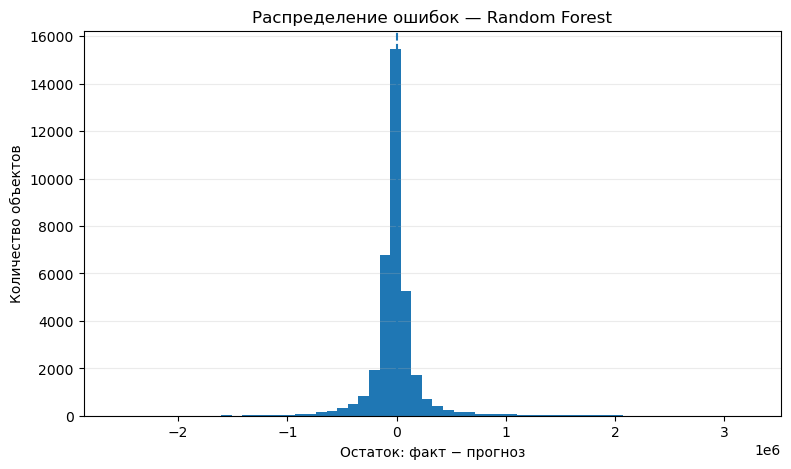

In [67]:
# Распределение ошибок модели
plt.figure(figsize=(9, 5))
plt.hist(residuals, bins=60)
plt.axvline(0, linestyle="--")
plt.xlabel("Остаток: факт − прогноз")
plt.ylabel("Количество объектов")
plt.title(f"Распределение ошибок — {best_model_name}")
plt.grid(axis="y", alpha=0.25)
plt.show()

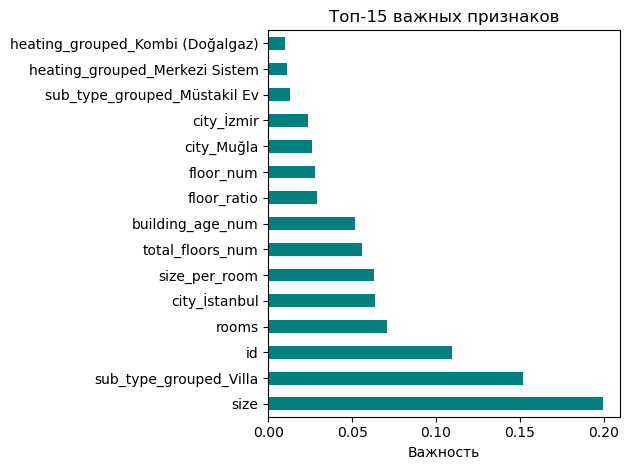

In [68]:
feat_imp = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
feat_imp.plot(kind='barh', color='teal')
plt.title('Топ-15 важных признаков')
plt.xlabel('Важность')
plt.tight_layout()
plt.show()

In [69]:
# Сохраняем лучшую модель и подготовленные данные в текущую папку
import joblib

joblib.dump(best_model, 'best_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(imputer, 'imputer.pkl')
joblib.dump(X_train.columns.tolist(), 'feature_names.pkl')

# Экспортируем данные для дашборда
df_dashboard = df_sale.sample(
    n=min(50000, len(df_sale)),
    random_state=42
).copy()
df_dashboard.to_csv('dashboard_data.csv', index=False, encoding='utf-8-sig')

print("Сохранены: best_model.pkl, scaler.pkl, imputer.pkl, feature_names.pkl, dashboard_data.csv")

Сохранены: best_model.pkl, scaler.pkl, imputer.pkl, feature_names.pkl, dashboard_data.csv


In [70]:
# Все файлы сохраняются в текущую папку ноутбука
SAVE_DIR = "."

joblib.dump(best_model, os.path.join(SAVE_DIR, 'best_model.pkl'))
joblib.dump(scaler, os.path.join(SAVE_DIR, 'scaler.pkl'))
joblib.dump(imputer, os.path.join(SAVE_DIR, 'imputer.pkl'))
joblib.dump(X_train.columns.tolist(), os.path.join(SAVE_DIR, 'feature_names.pkl'))

print("Модель и объекты предварительной обработки сохранены в:", os.path.abspath(SAVE_DIR))

Модель и объекты предварительной обработки сохранены в: C:\Users\mk20_\2026-2027\2


Проект демонстрирует полный цикл разработки ML-решения: от исследования и очистки данных до сравнения нескольких регрессионных моделей, выбора лучшей по совокупности метрик и отдельной проверки на тестовых объектах. Предобработка обучающих и тестовых данных выполняется раздельно, чтобы не допускать утечки информации. Финальные результаты и ограничения модели интерпретируются с учётом размера тестовой выборки.

In [71]:
target_path = "data_for_datalens.csv"

# Берем нужные исходные столбцы из df_sale
df_datalens = df_sale[['price', 'size', 'room_count', 'building_age', 'address', 'sub_type', 'heating_type']].copy()

# Извлекаем город и район из адреса
df_datalens['city'] = df_datalens['address'].str.split('/').str[0].str.strip()
df_datalens['district'] = df_datalens['address'].str.split('/').str[1].str.strip()

# Извлекаем числа из текстовых полей (комнаты и возраст здания)
df_datalens['rooms'] = df_datalens['room_count'].str.extract(r'(\d+)').astype(float)
df_datalens['age'] = df_datalens['building_age'].str.extract(r'(\d+)').astype(float)

# Оставляем только целевые столбцы для дашборда (строго без One-Hot Encoding)
df_datalens = df_datalens[['price', 'size', 'rooms', 'age', 'city', 'district', 'sub_type', 'heating_type']]

# Удаляем строки с пропусками в ключевых полях
df_datalens = df_datalens.dropna(subset=['price', 'size', 'city', 'rooms'])

# Убираем экстремальные выбросы по цене (1% и 99% перцентили), чтобы графики в DataLens были читаемыми
q_low = df_datalens['price'].quantile(0.01)
q_high = df_datalens['price'].quantile(0.99)
df_datalens = df_datalens[(df_datalens['price'] >= q_low) & (df_datalens['price'] <= q_high)]

# Сохраняем в CSV с правильной кодировкой для Excel/DataLens
df_datalens.to_csv(target_path, index=False, encoding='utf-8-sig')
print(f"Файл data_for_datalens.csv успешно создан! Размер: {df_datalens.shape}")

Файл data_for_datalens.csv успешно создан! Размер: (175731, 8)


In [72]:
target_path = "data_for_datalens_small.csv"
df_small = df_datalens.sample(n=min(10000, len(df_datalens)), random_state=42)
df_small.to_csv(target_path, index=False, encoding='utf-8-sig')
print(f"Размер уменьшенного файла: {df_small.shape}")

Размер уменьшенного файла: (10000, 8)


Ссылка на дашборд: https://datalens.ru/afmt8cqod5yut-vizualizaciya-prognozirovaniya-stoimosti-nedvizhimosti?state=d535ce15183

# Этап 4. Проверка модели на тестовых объектах

На предыдущих этапах были исследованы данные о недвижимости, выполнена подготовка признаков и рассмотрены модели регрессии. На этом этапе проверим прогнозы на отдельном файле `test_real_estate_samples.csv`, содержащем 20 объектов.

Для обучения используется исходный файл `real_estate_data.csv`. Идентификаторы тестовых объектов исключаются из обучения, чтобы модель не видела эти объекты заранее. Так как проект посвящён прогнозированию цены продажи, метрики рассчитываются только для объявлений о продаже с известной фактической ценой. Арендные объявления остаются в итоговой таблице, но прогноз для них не рассчитывается.

## 4.1. Загрузка исходных и тестовых данных

Загружаем исходный набор данных для обучения и отдельный тестовый файл. Сначала проверяем размеры таблиц и просматриваем тестовые записи, чтобы убедиться, что данные прочитаны корректно.

In [73]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

raw_full_test = pd.read_csv("real_estate_data.csv", low_memory=False)
test_samples = pd.read_csv("test_real_estate_samples.csv", low_memory=False)

print("Размер исходного датасета:", raw_full_test.shape)
print("Размер тестового файла:", test_samples.shape)
display(test_samples.head())

Размер исходного датасета: (403487, 17)
Размер тестового файла: (20, 17)


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,49,Konut,Kooperatif,11/10/18,12/10/18,1,30,0,10,Müstakil,1+0,1.0,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY
1,506,Konut,Çiftlik Evi,10/25/18,2/23/19,1,121,2,2,NaN,2+2,250.0,İzmir/Foça/Yeniköy,NaN,Yok,1600000.0,TRY
2,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY
3,528,Konut,Prefabrik Ev,11/16/18,1/21/19,1,66,NaN,1,NaN,3+1,122.0,Tekirdağ/Çerkezköy/Kızılpınar,NaN,Yok,103600.0,TRY
4,109,Konut,Kooperatif,11/10/18,1/9/19,1,60,0,10,Müstakil,1+0,1.0,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY


## 4.2. Подготовка обучающей выборки

Оставляем объявления о продаже с положительной ценой в TRY, удаляем полные дубликаты и исключаем из обучения идентификаторы тестовых объектов. После этого ограничиваем обучающие цены диапазоном от 1-го до 99-го процентиля, чтобы уменьшить влияние крайних значений. Фильтрация применяется только к обучающим данным, а тестовые цены сохраняются для независимой оценки.

In [74]:
test_ids = set(test_samples["id"].dropna())

train_test = raw_full_test.drop_duplicates().copy()
train_test = train_test[
    (train_test["listing_type"] == 1) &
    (train_test["price_currency"] == "TRY") &
    (train_test["price"] > 0)
].copy()

# Исключаем тестовые объекты из обучающей выборки
train_test = train_test[~train_test["id"].isin(test_ids)].copy()

q_low = train_test["price"].quantile(0.01)
q_high = train_test["price"].quantile(0.99)
train_test = train_test[train_test["price"].between(q_low, q_high)].copy()

print("Объектов для обучения:", len(train_test))
print("Диапазон цен в обучающей выборке:", round(q_low, 2), "—", round(q_high, 2), "TRY")
print("Тестовых ID, найденных в исходных данных:", len(test_ids.intersection(set(raw_full_test["id"]))))

Объектов для обучения: 278796
Диапазон цен в обучающей выборке: 63500.0 — 3700000.0 TRY
Тестовых ID, найденных в исходных данных: 20


## 4.3. Создание признаков

Чтобы модель могла использовать характеристики объектов, преобразуем текстовые поля в числовые признаки: извлекаем город, количество комнат, возраст здания, число этажей и номер этажа. Также добавляем простые признаки — площадь на комнату, новый ли дом и относительное положение этажа.

Для категориальных признаков оставляем наиболее частые типы недвижимости и отопления, а остальные объединяем в категорию «Other». Список категорий определяется только по обучающим данным.

In [75]:
def make_test_features(data, top_subtypes, top_heating):
    d = data.copy()

    # Город из адреса
    d["city"] = (
        d["address"].fillna("Unknown").astype(str)
        .str.split("/").str[0].str.strip()
    )

    # Комнаты: например, "3+1"
    room_text = d["room_count"].fillna("").astype(str)
    d["rooms"] = pd.to_numeric(
        room_text.str.extract(r"^(\d+)")[0], errors="coerce"
    )
    d["living_rooms"] = pd.to_numeric(
        room_text.str.extract(r"\+(\d+)")[0], errors="coerce"
    ).fillna(0)

    # Возраст здания и количество этажей
    d["building_age_num"] = pd.to_numeric(
        d["building_age"].fillna("").astype(str).str.extract(r"(\d+)")[0],
        errors="coerce"
    )
    d["total_floors_num"] = pd.to_numeric(
        d["total_floor_count"].fillna("").astype(str).str.extract(r"^(\d+)")[0],
        errors="coerce"
    )

    floor = d["floor_no"].fillna("").astype(str)
    d["floor_num"] = pd.to_numeric(
        floor.str.extract(r"^(\d+)")[0], errors="coerce"
    ).fillna(0)
    d["is_penthouse"] = floor.str.contains(
        r"Çatı|En Üst", case=False, regex=True
    ).astype(int)
    d["is_garden"] = floor.str.contains(
        "Bahçe", case=False, regex=False
    ).astype(int)
    d["is_ground"] = floor.str.contains(
        r"Giriş|Zemin|Kot|Yüksek", case=False, regex=True
    ).astype(int)

    d["size"] = pd.to_numeric(d["size"], errors="coerce")
    d["size_per_room"] = d["size"] / (d["rooms"] + 1)
    d["is_new_building"] = (d["building_age_num"] <= 5).astype(int)
    d["floor_ratio"] = d["floor_num"] / (d["total_floors_num"] + 1)
    d["has_living_room"] = (d["living_rooms"] > 0).astype(int)

    subtype = d["sub_type"].fillna("Unknown")
    heating = d["heating_type"].fillna("Unknown")
    d["sub_type_grouped"] = subtype.where(subtype.isin(top_subtypes), "Other")
    d["heating_grouped"] = heating.where(heating.isin(top_heating), "Other")

    feature_columns = [
        "size", "rooms", "living_rooms", "building_age_num",
        "total_floors_num", "is_penthouse", "is_garden", "is_ground",
        "floor_num", "size_per_room", "is_new_building", "floor_ratio",
        "has_living_room", "sub_type_grouped", "heating_grouped",
        "price_currency", "city"
    ]

    X = d[feature_columns].copy()
    X = pd.get_dummies(
        X,
        columns=[
            "sub_type_grouped", "heating_grouped",
            "price_currency", "city"
        ],
        drop_first=True,
        dtype=int
    )
    return X

## 4.4. Подготовка обучающих и тестовых признаков

Выбираем из тестового файла только объявления о продаже. Затем создаём признаки для обучающих и тестовых объектов и выравниваем столбцы, чтобы в обеих таблицах использовался одинаковый набор признаков.

Пропуски заполняются медианой, рассчитанной на обучающей выборке. Масштабирование также настраивается только на обучающих данных и затем применяется к тестовым объектам.

In [76]:
top_subtypes = (
    train_test["sub_type"].fillna("Unknown").value_counts().head(5).index
)
top_heating = (
    train_test["heating_type"].fillna("Unknown").value_counts().head(6).index
)

sale_test = test_samples[test_samples["listing_type"] == 1].copy()
sale_test = sale_test[sale_test["price"].notna() & (sale_test["price"] > 0)].copy()

X_train_test = make_test_features(train_test, top_subtypes, top_heating)
X_sale_test = make_test_features(sale_test, top_subtypes, top_heating)

# Согласуем столбцы по обучающей матрице
X_sale_test = X_sale_test.reindex(columns=X_train_test.columns, fill_value=0)

y_train_test = train_test["price"].astype(float).to_numpy()

imputer_test = SimpleImputer(strategy="median")
X_train_imp_test = imputer_test.fit_transform(X_train_test)
X_sale_imp_test = imputer_test.transform(X_sale_test)

scaler_test = RobustScaler()
X_train_scaled_test = scaler_test.fit_transform(X_train_imp_test)
X_sale_scaled_test = scaler_test.transform(X_sale_imp_test)

print("Размер обучающей матрицы:", X_train_scaled_test.shape)
print("Размер тестовой матрицы продажи:", X_sale_scaled_test.shape)
print("Число тестовых продаж для оценки:", len(sale_test))

Размер обучающей матрицы: (278796, 102)
Размер тестовой матрицы продажи: (10, 102)
Число тестовых продаж для оценки: 10


## 4.5. Обучение модели Random Forest

Для проверки используется Random Forest — модель, которая объединяет несколько деревьев решений. Чтобы обучение выполнялось быстрее, из подготовленных обучающих данных случайным образом выбирается не более 20 000 объектов. Параметр `random_state=42` обеспечивает воспроизводимость результата.

In [77]:
# Используем параметры выбранной на этапе сравнения Random Forest
rf_params_final = best_rf.get_params()

rng = np.random.RandomState(42)
chosen = rng.choice(
    len(X_train_scaled_test),
    size=min(20000, len(X_train_scaled_test)),
    replace=False
)

model_test = RandomForestRegressor(
    n_estimators=rf_params_final["n_estimators"],
    max_depth=rf_params_final["max_depth"],
    min_samples_split=rf_params_final["min_samples_split"],
    min_samples_leaf=rf_params_final["min_samples_leaf"],
    random_state=42,
    n_jobs=-1
)

model_test.fit(
    X_train_scaled_test[chosen],
    y_train_test[chosen]
)

y_pred_test = model_test.predict(X_sale_scaled_test)

print("Финальная модель:", type(model_test).__name__)
print("Параметры:", {
    "n_estimators": model_test.n_estimators,
    "max_depth": model_test.max_depth,
    "min_samples_split": model_test.min_samples_split,
    "min_samples_leaf": model_test.min_samples_leaf
})
print("Количество объектов для обучения:", len(chosen))
print("Количество рассчитанных прогнозов:", len(y_pred_test))

Финальная модель: RandomForestRegressor
Параметры: {'n_estimators': 200, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 1}
Количество объектов для обучения: 20000
Количество рассчитанных прогнозов: 10


## 4.6. Итоговая таблица прогнозов

Добавляем к исходному тестовому файлу два поля для заполнения — ФИО и группу, а также статус применения модели. Прогноз записывается только для объявлений о продаже. Для аренды значение прогноза остаётся пустым, поскольку эта модель не обучалась прогнозировать арендную плату.

Итоговая таблица сохраняется в файл `result_real_estate_samples.csv`.

In [80]:
result_test = test_samples.copy()
result_test["ФИО"] = "Маликова Камалия Илшатовна"
result_test["Группа"] = "23П-1"
result_test["Статус модели"] = np.where(
    result_test["listing_type"] == 1,
    "Продажа: прогноз рассчитан",
    "Аренда: вне области модели продажи"
)
result_test["Прогноз модели (TRY)"] = np.nan

# Записываем прогнозы в строки тех продаж, которые действительно оценивались
result_test.loc[sale_test.index, "Прогноз модели (TRY)"] = y_pred_test

display(result_test)
result_test.to_csv(
    "result_real_estate_samples.csv",
    index=False,
    encoding="utf-8-sig"
)
print("Файл result_real_estate_samples1.csv сохранён.")

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,...,size,address,furnished,heating_type,price,price_currency,ФИО,Группа,Статус модели,Прогноз модели (TRY)
0,49,Konut,Kooperatif,11/10/18,12/10/18,1,30,0,10,Müstakil,...,1.0,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,496681.666667
1,506,Konut,Çiftlik Evi,10/25/18,2/23/19,1,121,2,2,NaN,...,250.0,İzmir/Foça/Yeniköy,NaN,Yok,1600000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,549237.803501
2,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,...,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,308425.000000
3,528,Konut,Prefabrik Ev,11/16/18,1/21/19,1,66,NaN,1,NaN,...,122.0,Tekirdağ/Çerkezköy/Kızılpınar,NaN,Yok,103600.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,193431.673118
4,109,Konut,Kooperatif,11/10/18,1/9/19,1,60,0,10,Müstakil,...,1.0,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,496681.666667
5,100,Konut,Yazlık,1/12/19,NaN,1,46,1,10,9,...,150.0,Mersin/Erdemli/Kargıpınarı,NaN,Fancoil,500000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,355492.111502
6,320,Konut,Yazlık,2/12/19,2/12/19,1,0,0,2,Müstakil,...,134.0,Balıkesir/Burhaniye/Pelitköy,NaN,Fancoil,1000000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,494449.300453
7,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,...,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,194469.585937
8,7810,Konut,Loft,12/30/18,1/29/19,1,30,NaN,4,NaN,...,145.0,İzmir/Konak/Akın Simav,NaN,Kalorifer (Doğalgaz),650000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,449817.712968
9,11,Konut,Müstakil Ev,11/13/18,11/26/18,1,13,0,1,Bahçe katı,...,125.0,Muğla/Bodrum/Ortakentyahşi,NaN,Fancoil,2450000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа: прогноз рассчитан,950440.595238


Файл result_real_estate_samples1.csv сохранён.


## 4.7. Оценка качества прогнозирования

Качество проверяется на тестовых объявлениях о продаже, у которых известна фактическая цена.

- **MAE** — средняя абсолютная ошибка в TRY. Чем меньше значение, тем ближе прогнозы к фактическим ценам.
- **RMSE** — корень из средней квадратичной ошибки; сильнее реагирует на большие отклонения.
- **R²** — коэффициент детерминации. Значение 1 соответствует идеальному прогнозу, около 0 — результату на уровне предсказания средней цены, отрицательное значение — результату хуже такого базового прогноза.

Сначала метрики рассчитываются вручную, затем проверяются с помощью функций `sklearn`.

In [81]:
y_true_test = sale_test["price"].astype(float).to_numpy()
mae_manual_test = np.mean(np.abs(y_true_test - y_pred_test))
rmse_manual_test = np.sqrt(np.mean((y_true_test - y_pred_test) ** 2))

ss_res_test = np.sum((y_true_test - y_pred_test) ** 2)
ss_tot_test = np.sum((y_true_test - np.mean(y_true_test)) ** 2)
r2_manual_test = 1 - ss_res_test / ss_tot_test if ss_tot_test != 0 else np.nan

mae_sklearn_test = mean_absolute_error(y_true_test, y_pred_test)
rmse_sklearn_test = np.sqrt(mean_squared_error(y_true_test, y_pred_test))
r2_sklearn_test = r2_score(y_true_test, y_pred_test)

metrics_test = pd.DataFrame({
    "Метрика": ["MAE", "RMSE", "R²"],
    "Ручной расчёт": [mae_manual_test, rmse_manual_test, r2_manual_test],
    "Расчёт sklearn": [mae_sklearn_test, rmse_sklearn_test, r2_sklearn_test]
})
display(metrics_test.round(4))

,Метрика,Ручной расчёт,Расчёт sklearn
0,MAE,410480.2069,410480.2069
1,RMSE,615571.3609,615571.3609
2,R²,0.2409,0.2409


In [82]:
# Проверка совпадения ручного расчёта и sklearn
metrics_test["Разница"] = (
    metrics_test["Ручной расчёт"] - metrics_test["Расчёт sklearn"]
).abs()

display(metrics_test.round(6))

print("Максимальная разница между ручным расчётом и sklearn:",
      metrics_test["Разница"].max())

,Метрика,Ручной расчёт,Расчёт sklearn,Разница
0,MAE,410480.206873,410480.206873,0.0
1,RMSE,615571.360935,615571.360935,0.0
2,R²,0.240887,0.240887,0.0


Максимальная разница между ручным расчётом и sklearn: 0.0


## 4.8. Ошибки по отдельным объектам

В таблице ниже сравниваются фактическая цена, прогноз модели и абсолютная ошибка для каждого тестового объявления о продаже. Эта таблица помогает увидеть не только общие метрики, но и объекты, на которых модель ошиблась сильнее всего.

In [83]:
details_test = sale_test[["id", "sub_type", "size", "room_count", "price"]].copy()
details_test = details_test.rename(columns={"price": "Фактическая цена (TRY)"})
details_test["Прогноз модели (TRY)"] = y_pred_test
details_test["Абсолютная ошибка (TRY)"] = np.abs(
    details_test["Фактическая цена (TRY)"].to_numpy() - y_pred_test
)
display(details_test.round(2))

,id,sub_type,size,room_count,Фактическая цена (TRY),Прогноз модели (TRY),Абсолютная ошибка (TRY)
0,49,Kooperatif,1.0,1+0,300000.0,496681.67,196681.67
1,506,Çiftlik Evi,250.0,2+2,1600000.0,549237.80,1050762.20
2,2,Daire,43.0,1+0,490000.0,308425.00,181575.00
3,528,Prefabrik Ev,122.0,3+1,103600.0,193431.67,89831.67
4,109,Kooperatif,1.0,1+0,300000.0,496681.67,196681.67
5,100,Yazlık,150.0,3+1,500000.0,355492.11,144507.89
6,320,Yazlık,134.0,4+1,1000000.0,494449.30,505550.70
7,3,Daire,NaN,2+1,155000.0,194469.59,39469.59
8,7810,Loft,145.0,4+1,650000.0,449817.71,200182.29
9,11,Müstakil Ev,125.0,3+1,2450000.0,950440.60,1499559.40


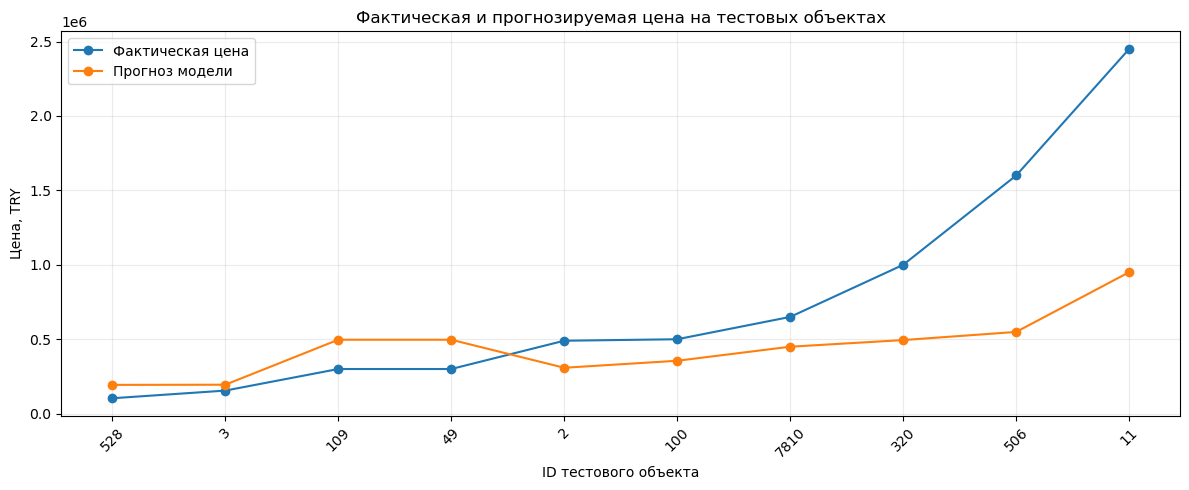

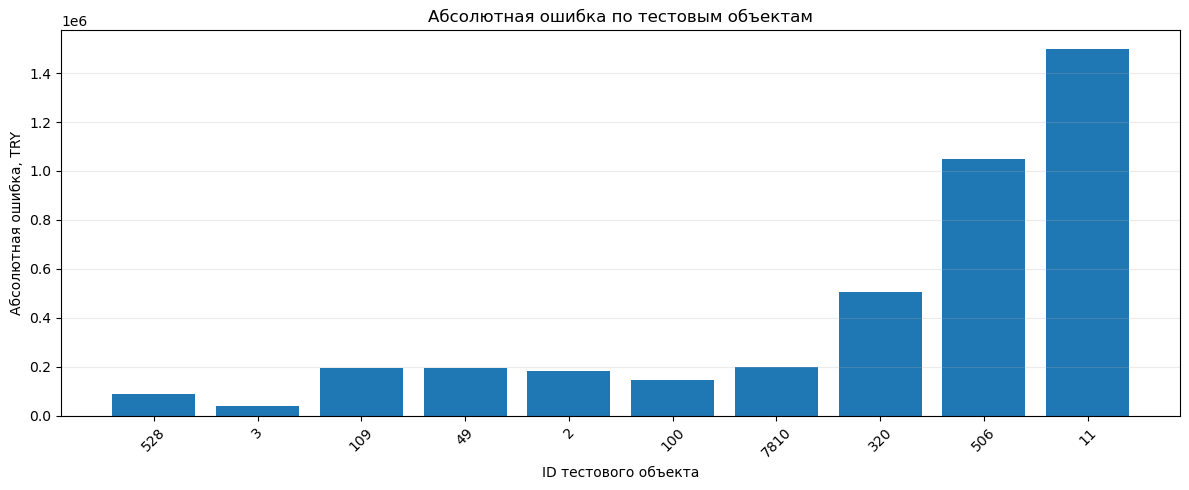

In [84]:
# Визуальная проверка прогнозов на отдельных тестовых объектах
plot_test = details_test.sort_values("Фактическая цена (TRY)").copy()

plt.figure(figsize=(12, 5))
plt.plot(
    plot_test["id"].astype(str),
    plot_test["Фактическая цена (TRY)"],
    marker="o",
    label="Фактическая цена"
)
plt.plot(
    plot_test["id"].astype(str),
    plot_test["Прогноз модели (TRY)"],
    marker="o",
    label="Прогноз модели"
)
plt.xlabel("ID тестового объекта")
plt.ylabel("Цена, TRY")
plt.title("Фактическая и прогнозируемая цена на тестовых объектах")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Абсолютная ошибка по каждому тестовому объекту
plt.figure(figsize=(12, 5))
plt.bar(
    plot_test["id"].astype(str),
    plot_test["Абсолютная ошибка (TRY)"]
)
plt.xlabel("ID тестового объекта")
plt.ylabel("Абсолютная ошибка, TRY")
plt.title("Абсолютная ошибка по тестовым объектам")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 4.9. Вывод по проверке модели

Полученные метрики показывают точность модели на тестовых объявлениях о продаже. MAE отражает средний размер ошибки в турецких лирах, RMSE показывает влияние крупных ошибок, а R² характеризует качество прогнозирования относительно базового прогноза средней цены.

Следует учитывать, что в тестовом файле только десять объявлений о продаже. Поэтому несколько крупных ошибок могут заметно влиять на общие метрики. Результаты относятся к этой тестовой выборке и не гарантируют такую же точность для всех объектов недвижимости.

### Визуальный анализ тестовых прогнозов
График фактических и прогнозируемых цен позволяет увидеть, насколько близко прогнозы расположены к реальным значениям. График абсолютных ошибок показывает, какие отдельные объекты сильнее всего влияют на итоговые MAE и RMSE. При небольшом количестве тестовых продаж несколько крупных ошибок могут существенно изменить итоговые метрики.